In [1]:
import numpy as np
import matplotlib.pyplot as plt
import mglearn
import tensorflow as tf
from sklearn.datasets import fetch_lfw_people 
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA 
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential 
from tensorflow.keras.layers import Input, Dense 

In [2]:
np.random.seed(180)
tf.random.set_seed(180) 

Data Shape : (3023, 5655)
Target Shape : (3023,)
Image Shape : (87, 65)
Number of Classes : 62
Target Names : ['Alejandro Toledo' 'Alvaro Uribe' 'Amelie Mauresmo' 'Andre Agassi'
 'Angelina Jolie' 'Ariel Sharon' 'Arnold Schwarzenegger'
 'Atal Bihari Vajpayee' 'Bill Clinton' 'Carlos Menem' 'Colin Powell'
 'David Beckham' 'Donald Rumsfeld' 'George Robertson' 'George W Bush'
 'Gerhard Schroeder' 'Gloria Macapagal Arroyo' 'Gray Davis'
 'Guillermo Coria' 'Hamid Karzai' 'Hans Blix' 'Hugo Chavez' 'Igor Ivanov'
 'Jack Straw' 'Jacques Chirac' 'Jean Chretien' 'Jennifer Aniston'
 'Jennifer Capriati' 'Jennifer Lopez' 'Jeremy Greenstock' 'Jiang Zemin'
 'John Ashcroft' 'John Negroponte' 'Jose Maria Aznar'
 'Juan Carlos Ferrero' 'Junichiro Koizumi' 'Kofi Annan' 'Laura Bush'
 'Lindsay Davenport' 'Lleyton Hewitt' 'Luiz Inacio Lula da Silva'
 'Mahmoud Abbas' 'Megawati Sukarnoputri' 'Michael Bloomberg' 'Naomi Watts'
 'Nestor Kirchner' 'Paul Bremer' 'Pete Sampras' 'Recep Tayyip Erdogan'
 'Ricardo Lagos' 'R

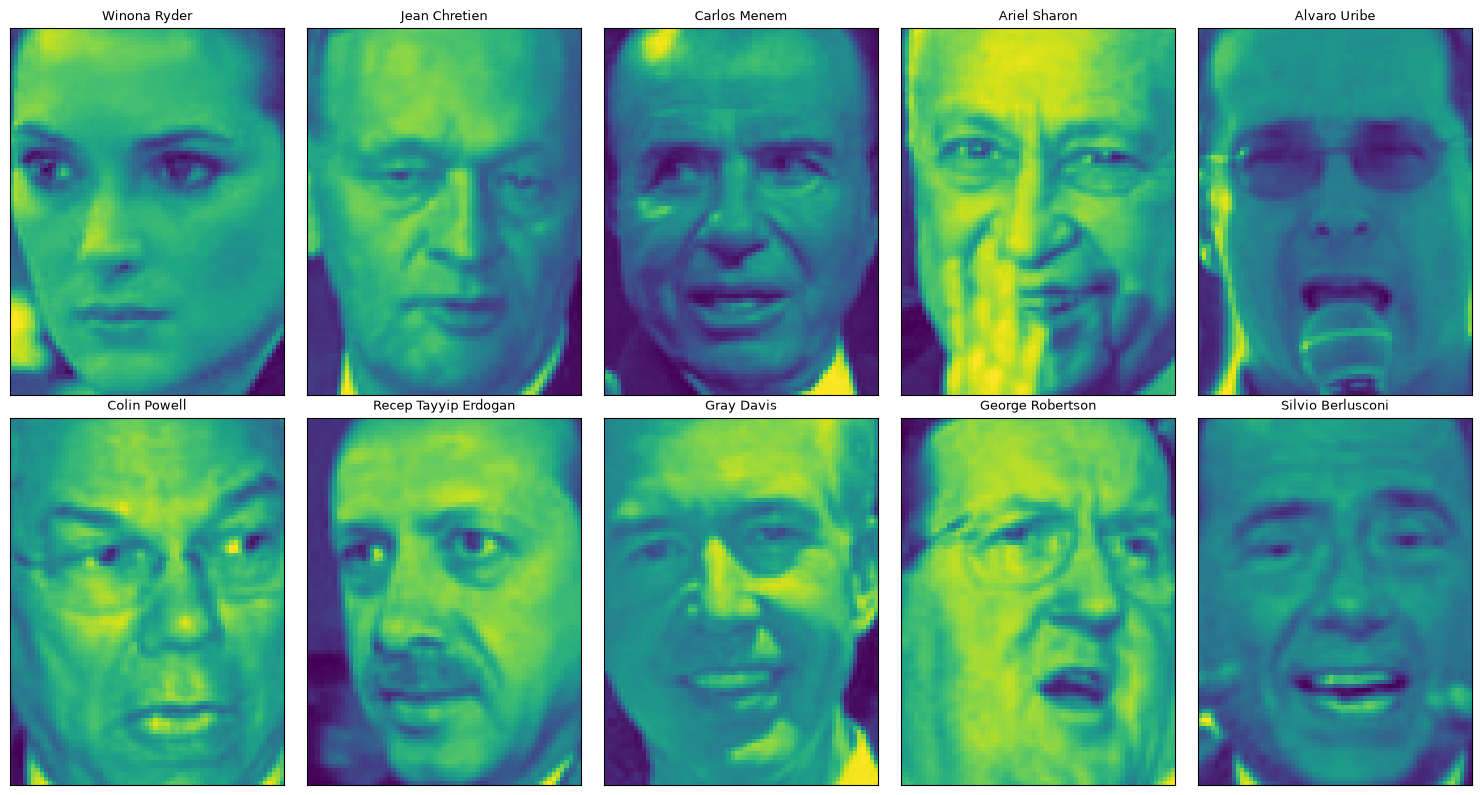

In [6]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_lfw_people

# -----------------------------
# Random Seed
# -----------------------------
np.random.seed(180)
tf.random.set_seed(180)

# -----------------------------
# Load the LFW Dataset
# -----------------------------
people = fetch_lfw_people(
    min_faces_per_person=20,
    resize=0.7
)

# -----------------------------
# Print Dataset Information
# -----------------------------
print("Data Shape :", people.data.shape)
print("Target Shape :", people.target.shape)

# Image Shape
image_shape = people.images[0].shape
print("Image Shape :", image_shape)

# Target Names
print("Number of Classes :", len(people.target_names))
print("Target Names :", people.target_names)

# -----------------------------
# Display Sample Faces
# -----------------------------
fig, axes = plt.subplots(
    2,
    5,
    figsize=(15, 8),
    subplot_kw={
        'xticks': (),
        'yticks': ()
    }
)

for target, image, ax in zip(
        people.target,
        people.images,
        axes.ravel()):

    # Colored output (Viridis)
    ax.imshow(image, cmap='viridis')

    # Person name
    ax.set_title(
        people.target_names[target],
        fontsize=9
    )

plt.tight_layout()
plt.show()

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    people.data,  
    people.target,  
    test_size=0.2,  
    random_state=20
)  

y_train = y_train.astype(int)
y_test = y_test.astype(int) 

batch_size = len(X_train) 

print(    
    X_train.shape, 
    y_train.shape, 
    y_test.shape 
)  

print(   
    "people.images.shape: {}".format(       
        people.images.shape
    )
)

print(  
    "Number of classes: {}".format( 
        len(people.target_names) 
    )
) 

(2418, 5655) (2418,) (605,)
people.images.shape: (3023, 87, 65)
Number of classes: 62


In [9]:
import numpy as np

# Count the number of images for each person
counts = np.bincount(people.target)

# Print the count of images for each person
for i, (count, name) in enumerate(zip(counts, people.target_names)):
    print("{0:25} {1:3}".format(name, count), end="  ")

    # Print 3 names per line
    if (i + 1) % 3 == 0:
        print()

Alejandro Toledo           39  Alvaro Uribe               35  Amelie Mauresmo            21  
Andre Agassi               36  Angelina Jolie             20  Ariel Sharon               77  
Arnold Schwarzenegger      42  Atal Bihari Vajpayee       24  Bill Clinton               29  
Carlos Menem               21  Colin Powell              236  David Beckham              31  
Donald Rumsfeld           121  George Robertson           22  George W Bush             530  
Gerhard Schroeder         109  Gloria Macapagal Arroyo    44  Gray Davis                 26  
Guillermo Coria            30  Hamid Karzai               22  Hans Blix                  39  
Hugo Chavez                71  Igor Ivanov                20  Jack Straw                 28  
Jacques Chirac             52  Jean Chretien              55  Jennifer Aniston           21  
Jennifer Capriati          42  Jennifer Lopez             21  Jeremy Greenstock          24  
Jiang Zemin                20  John Ashcroft              53

In [10]:
mask = np.zeros(
    people.target.shape,  
    dtype=np.bool_
) 

for target in np.unique(people.target): 
    
    mask[   
        np.where(people.target == target)[0][:50]  
        ] = True
    X_people = people.data[mask]
    
    y_people = people.target[mask]
    # Scale pixel values
    X_people = X_people / 255.0 

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X_people,    
    y_people,   
    stratify=y_people, 
    random_state=0
) 
# KNN without PCA 
knn = KNeighborsClassifier( 
    n_neighbors=1 
) 

knn.fit( 
    X_train, 
    y_train 
)
print( 
    "Test set score of 1-nn: {:.2f}".format( 
        knn.score( 
            X_test,
            y_test
        ) 
    )
) 

Test set score of 1-nn: 0.22


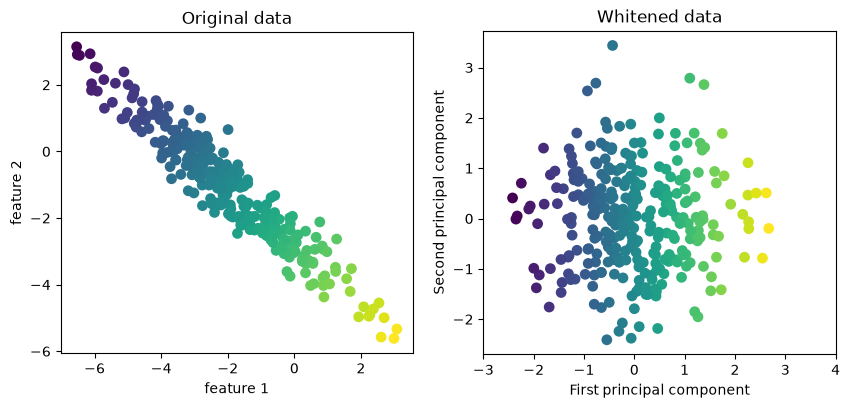

In [13]:
mglearn.plots.plot_pca_whitening()
plt.show() 

pca.components_.shape: (100, 5655)


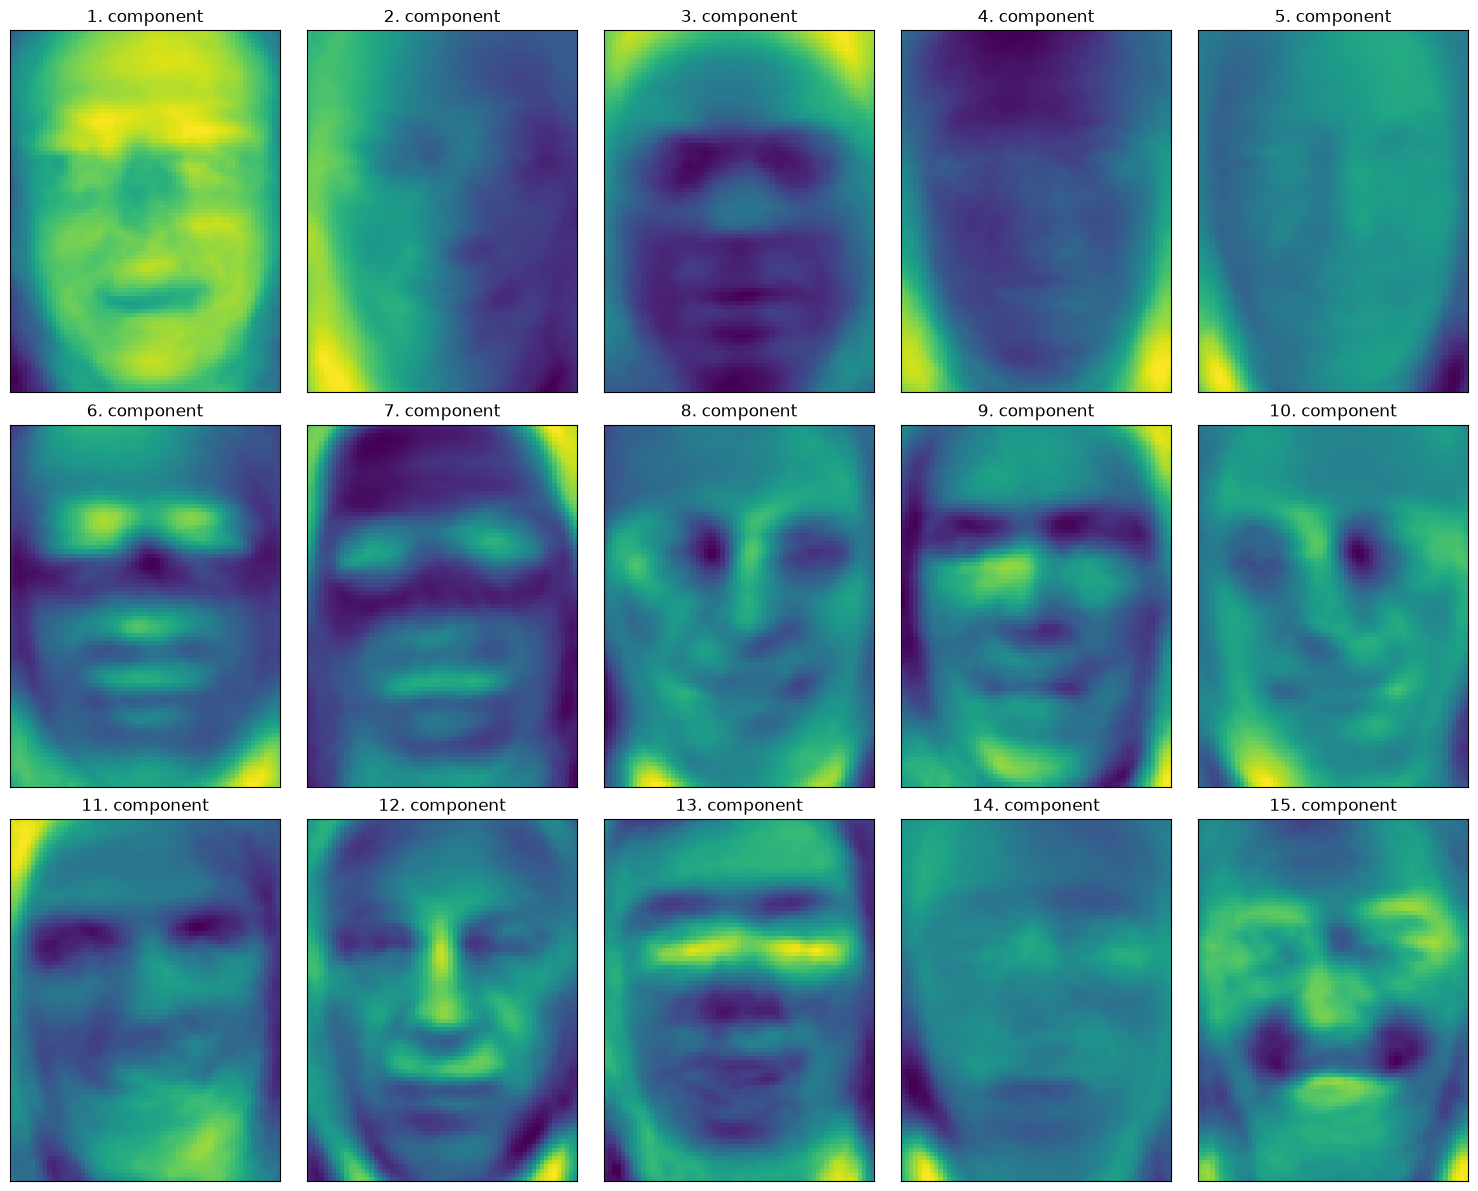

In [16]:
# Print PCA component shape
print("pca.components_.shape: {}".format(
    pca.components_.shape)
)

# PCA Components
fig, axes = plt.subplots(
    3,
    5,
    figsize=(15, 12),
    subplot_kw={'xticks': (), 'yticks': ()}
)

for i, (component, ax) in enumerate(
        zip(pca.components_, axes.ravel())):

    ax.imshow(
        component.reshape(image_shape),
        cmap='viridis'
    )

    ax.set_title(
        "{}. component".format(i + 1)
    )

plt.tight_layout()
plt.show()

In [17]:
# Scaling PCA features
scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(
    X_train_pca
)
X_test_scaled = scaler.transform(
    X_test_pca
)

In [18]:
model = Sequential([ 
    
    Input(     
        shape=(100,)     
    ), 
    
    Dense(
        300,
        activation='relu'  
    ),    
    
    Dense( 
        100, 
        activation='relu' 
    ),  
    
    Dense(    
        len(np.unique(y_train)), 
        activation='softmax'   
    )
]) 

In [19]:
model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy']) 